<a href="https://colab.research.google.com/github/Blessy373/Data-Analytics/blob/main/KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('/content/income.csv')

In [3]:
df

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000
8,Brad,36,156000
9,Angelina,35,130000


In [4]:
import matplotlib.pyplot as plt


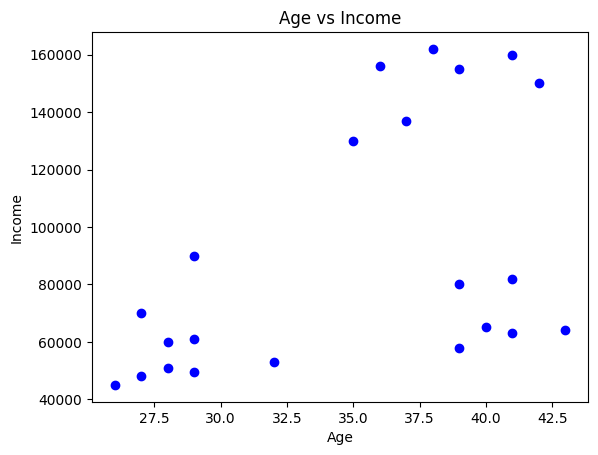

In [5]:
plt.scatter(df['Age'],df['Income($)'],color='blue')
plt.xlabel('Age')
plt.ylabel('Income')
plt.title('Age vs Income')
plt.show()

In [7]:
from sklearn.cluster import KMeans
k=KMeans(n_clusters=3)
pred=k.fit_predict(df[['Age','Income($)']])

In [8]:
df['pred']=pred

In [9]:
k.cluster_centers_

array([[3.29090909e+01, 5.61363636e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.40000000e+01, 8.05000000e+04]])

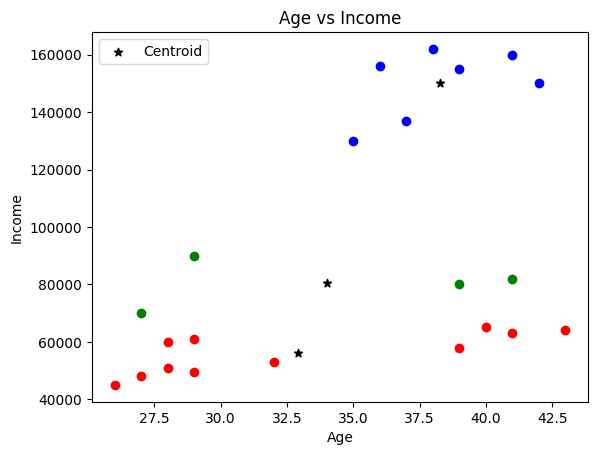

In [13]:
df1=df[df['pred']==0]
df2=df[df['pred']==1]
df3=df[df['pred']==2]
plt.scatter(df1['Age'],df1['Income($)'],color='red')
plt.scatter(df2['Age'],df2['Income($)'],color='blue')
plt.scatter(df3['Age'],df3['Income($)'],color='green')
plt.scatter(k.cluster_centers_[:,0],k.cluster_centers_[:,1],marker='*',color='black',label='Centroid')
plt.xlabel('Age')
plt.ylabel('Income')
plt.title('Age vs Income')
plt.legend()
plt.show()

In [14]:
from sklearn.preprocessing import MinMaxScaler
mm=MinMaxScaler()

In [15]:
df['Age']= mm.fit_transform(df[['Age']])
df['Income($)']= mm.fit_transform(df[['Income($)']])


In [17]:
kk=KMeans(n_clusters=3)
predi=kk.fit_predict(df[['Age','Income($)']])

In [18]:
df['Real_pred']=predi

In [19]:
df['pred']==df['Real_pred']

,0
0,False
1,False
2,False
3,False
4,False
5,False
6,False
7,False
8,False
9,False


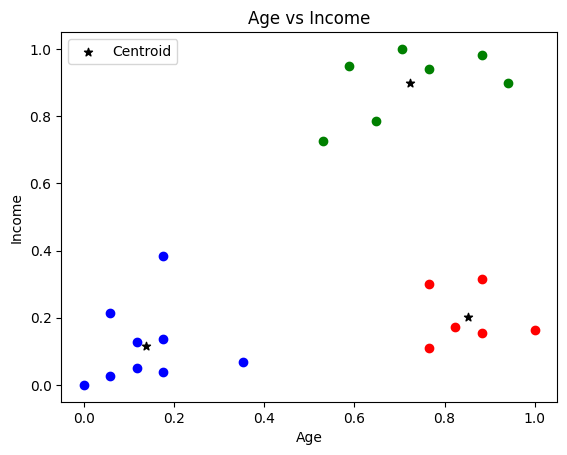

In [20]:
dff1=df[df['Real_pred']==0]
dff2=df[df['Real_pred']==1]
dff3=df[df['Real_pred']==2]
plt.scatter(dff1['Age'],dff1['Income($)'],color='red')
plt.scatter(dff2['Age'],dff2['Income($)'],color='blue')
plt.scatter(dff3['Age'],dff3['Income($)'],color='green')
plt.scatter(kk.cluster_centers_[:,0],kk.cluster_centers_[:,1],marker='*',color='black',label='Centroid')
plt.xlabel('Age')
plt.ylabel('Income')
plt.title('Age vs Income')
plt.legend()
plt.show()

Finding best K val:

In [22]:
error=[]
ks=range(1,10)
for k in ks:
 km=KMeans(n_clusters=k)
 km.fit(df[['Age','Income($)']])
 error.append(km.inertia_)


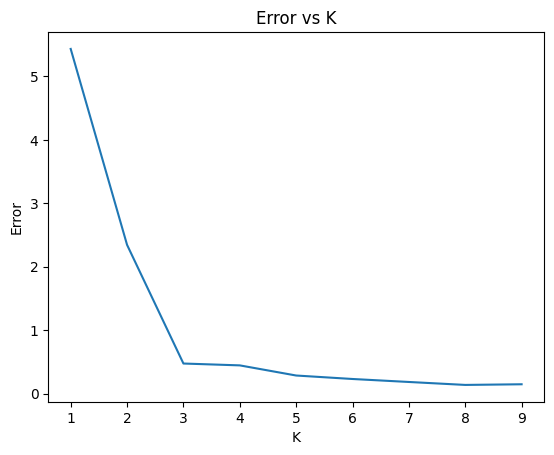

In [25]:
plt.plot(ks,error)
plt.xlabel('K')
plt.ylabel('Error')
plt.title('Error vs K')
plt.show()